In [7]:
import yfinance as yf
import pandas as pd
nvda=yf.Ticker("NVDA").info
nvda['sector']

'Technology'

In [10]:
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime

def plot_ticker_performance(tickers, start_date, end_date):
    """
    Fetches stock price data for specified tickers over a date range and plots the prices.

    Parameters:
        tickers (list of str): Stock tickers to retrieve data for.
        start_date (str): Start date in 'YYYY-MM-DD' format.
        end_date (str): End date in 'YYYY-MM-DD' format.
    """
    # Basic date validation
    try:
        datetime.strptime(start_date, "%Y-%m-%d")
        datetime.strptime(end_date, "%Y-%m-%d")
    except ValueError:
        raise ValueError("Dates must be in 'YYYY-MM-DD' format")

    if not tickers:
        raise ValueError("Tickers list cannot be empty")

    # Download data (auto_adjust=True gives split/dividend-adjusted prices)
    data = yf.download(
        tickers,
        start=start_date,
        end=end_date,
        auto_adjust=True,
        progress=False,
        threads=True
    )
    print(data)
    if data.empty:
        raise ValueError("No data returned. Check tickers and date range.")

    # Extract Close prices
    if isinstance(data.columns, pd.MultiIndex):
        # Multiple tickers
        close_prices = data["Close"]
    else:
        # Single ticker
        close_prices = data["Close"].to_frame(name=tickers[0])

    # Plot
    plt.figure(figsize=(14, 7))
    close_prices.plot(linewidth=1.5)
    plt.title(f"Stock Price Performance\n{', '.join(tickers)}\n{start_date} → {end_date}")
    plt.xlabel("Date")
    plt.ylabel("Adjusted Close Price")
    plt.legend(title="Ticker", loc="best")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return close_prices  # optional: return the DataFrame if you want to use the data further

Price            Close                                            High  \
Ticker            AAPL        AMZN       GOOGL        MSFT        AAPL   
Date                                                                     
2023-01-03  122.876747   85.820000   88.279953  232.510529  128.604505   
2023-01-04  124.144119   85.139999   87.249756  222.339813  126.403789   
2023-01-05  122.827614   83.120003   85.387474  215.750137  125.529389   
2023-01-06  127.346962   86.080002   86.516739  218.292831  128.005211   
2023-01-09  127.867645   87.360001   87.190331  220.418182  131.070487   
...                ...         ...         ...         ...         ...   
2024-12-23  253.430862  225.059998  193.494339  429.338959  253.808114   
2024-12-24  256.339752  229.050003  194.965683  433.363495  256.349660   
2024-12-26  257.153778  227.050003  194.458679  432.160126  258.226014   
2024-12-27  253.748550  223.750000  191.635239  424.683075  256.836160   
2024-12-30  250.382965  221.300003  19

/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/nkb/papp/.venv/lib/python3.13/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_index(inplace=True)
/

<Figure size 1400x700 with 0 Axes>

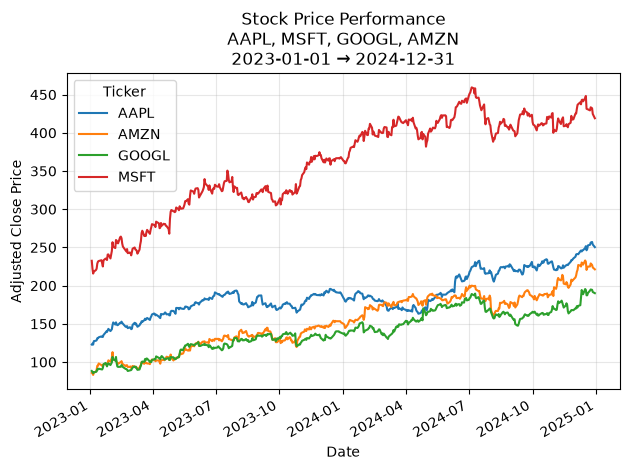

Ticker,AAPL,AMZN,GOOGL,MSFT
Date,,,,
2023-01-03,122.876747,85.820000,88.279953,232.510529
2023-01-04,124.144119,85.139999,87.249756,222.339813
2023-01-05,122.827614,83.120003,85.387474,215.750137
2023-01-06,127.346962,86.080002,86.516739,218.292831
2023-01-09,127.867645,87.360001,87.190331,220.418182
...,...,...,...,...
2024-12-23,253.430862,225.059998,193.494339,429.338959
2024-12-24,256.339752,229.050003,194.965683,433.363495
2024-12-26,257.153778,227.050003,194.458679,432.160126


In [11]:
tickers = ["AAPL", "MSFT", "GOOGL", "AMZN"]
plot_ticker_performance(tickers, "2023-01-01", "2024-12-31")